# 01_06 Zipf and Power Laws

**Learning objectives**
- Define the Zipf (zeta) distribution and the finite Zipfian over ranks, and recognise a power law on a log-log plot.
- Derive normalization and the mean and variance, and see why they may not exist for small exponents.
- Estimate the exponent from real word counts (Pride and Prejudice) and answer coverage questions.
- Distinguish the rank-frequency and the frequency-count views of the same data.

**Prerequisites:** [01_01 Bernoulli and Binomial](01_01_bernoulli_binomial.ipynb); lesson [01_05](01_05_uniform_categorical_multinomial.ipynb) (categorical draws).

## 1. Setup

All imports in one cell, seeded generator for reproducibility. The book text is read later from `../data/` (run `../data/download_data.py` if it is missing).

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **PMF** assigns probabilities to discrete values; they must sum to 1.
- The **expected value** $E[X]=\sum_kk\,P(X=k)$ exists only if this sum converges.
- A **p-series** $\sum_{k=1}^\infty k^{-a}$ converges if and only if $a>1$; its value is the **Riemann zeta function** $\zeta(a)$.
- **Harmonic number** $H_N=\sum_{k=1}^N1/k\approx\ln N+0.5772$.
- On a **log-log plot** a power law $y=Cx^{-s}$ is a straight line with slope $-s$, since $\log y=\log C-s\log x$.

## 3. Intuition and story

Count how often each word appears in a book and sort from most to least frequent. The most common word ("the") appears about twice as often as the second ("to"), three times as often as the third... Roughly, **frequency is proportional to 1/rank**. A few items are extremely common, and a **long tail** of items is very rare. The same shape appears in city sizes, website traffic, product sales, and song plays.

Two related models:
- **Zipf (zeta) distribution** with exponent $s>1$ on all ranks $1,2,3,\dots$: $P(X=k)\propto k^{-s}$.
- **Finite Zipfian** on ranks $1,\dots,N$ (a vocabulary of $N$ words), which is valid for any $s\ge0$ including $s\le1$.

The random variable is the **rank** of a randomly drawn word token.

## 4. Formal definition

**Zipf / zeta($s$)**, $s>1$: support $k\in\{1,2,\dots\}$,
$$P(X=k)=\frac{k^{-s}}{\zeta(s)},\qquad \zeta(s)=\sum_{j=1}^\infty j^{-s}.$$

**Zipfian($s,N$)**, any $s\ge0$: support $k\in\{1,\dots,N\}$,
$$P(X=k)=\frac{k^{-s}}{H_{N,s}},\qquad H_{N,s}=\sum_{j=1}^Nj^{-s}.$$
For $s=1$ this is $P(X=k)=\frac1{kH_N}$.

**Coverage:** the share of all tokens covered by the top $n$ ranks is $P(X\le n)=H_{n,s}/H_{N,s}$.

`scipy` names: `stats.zipf(a=s)` (zeta, $s>1$) and `stats.zipfian(a=s, n=N)` (finite).

## 5. Derivations

### 5.1 Normalization
By definition $\sum_{k\ge1}k^{-s}=\zeta(s)$, finite exactly when $s>1$. The integral test gives the reason: $\int_1^\infty x^{-s}dx=\frac1{s-1}<\infty$ iff $s>1$. For $s\le1$ the zeta sum diverges, so no infinite-support Zipf exists; the finite Zipfian is normalized by the finite sum $H_{N,s}$.

### 5.2 Mean
$$E[X]=\sum_{k\ge1}k\frac{k^{-s}}{\zeta(s)}=\frac1{\zeta(s)}\sum_{k\ge1}k^{-(s-1)}=\frac{\zeta(s-1)}{\zeta(s)},\qquad\text{finite iff }s-1>1,\text{ i.e. }s>2.$$
For $1<s\le2$ the mean is **infinite**.

### 5.3 Variance
$$E[X^2]=\frac{\zeta(s-2)}{\zeta(s)},\ \text{finite iff }s>3,\qquad\mathrm{Var}(X)=\frac{\zeta(s-2)}{\zeta(s)}-\Big(\frac{\zeta(s-1)}{\zeta(s)}\Big)^2.$$
For $2<s\le3$ the mean exists but the variance is **infinite**.

### 5.4 Consequences of infinite moments
The law of large numbers needs a finite mean, and the usual central-limit scaling needs a finite variance. For $s\le2$ the sample mean never settles (we will see this in section 9). Heavy tails are the reason.

### 5.5 Straight line on a log-log plot
$\log P(X=k)=-s\log k-\log\zeta(s)$: slope $-s$, intercept $-\log\zeta(s)$. Estimating $s$ means estimating that slope; a more principled approach is maximum likelihood (section 11).

### 5.6 Maximum likelihood for the finite Zipfian
For ranks $r_1,\dots,r_m$: $\ell(s)=-s\sum_i\ln r_i-m\ln H_{N,s}$. Setting $\ell'(s)=0$ gives $\frac1m\sum_i\ln r_i=\frac{\sum_jj^{-s}\ln j}{\sum_jj^{-s}}$, i.e. the model's expected log-rank equals the observed average log-rank. It has no closed form, so we solve it numerically.

### 5.7 MGF, skewness
The MGF $E[e^{tX}]$ is infinite for every $t>0$ (power-law tails are heavier than any exponential), so it does not exist. Skewness is defined only for $s>4$ and is strongly positive.

## 6. Properties and relationships

- **Scale-free:** $P(X=2k)/P(X=k)=2^{-s}$ for every $k$: doubling the rank always multiplies the frequency by the same factor.
- **Heavy tail:** $P(X>k)\sim k^{-(s-1)}/((s-1)\zeta(s))$, much slower than geometric or Poisson tails.
- **Continuous analogue:** the Pareto distribution (Module 02).
- **Rank-frequency vs frequency-count views:** sorting items by count and plotting count against rank (Zipf's law) is equivalent to plotting how many items have a given count (a power law with exponent $1+1/s$).
- **Generation mechanisms:** preferential attachment ("rich get richer") and multiplicative growth produce power laws.

## 7. 2D visuals

### 7.1 PMF and CDF of a Zipfian
A vocabulary of N = 50 ranks with s = 1. Rank 1 is most likely, then a slowly decaying tail.

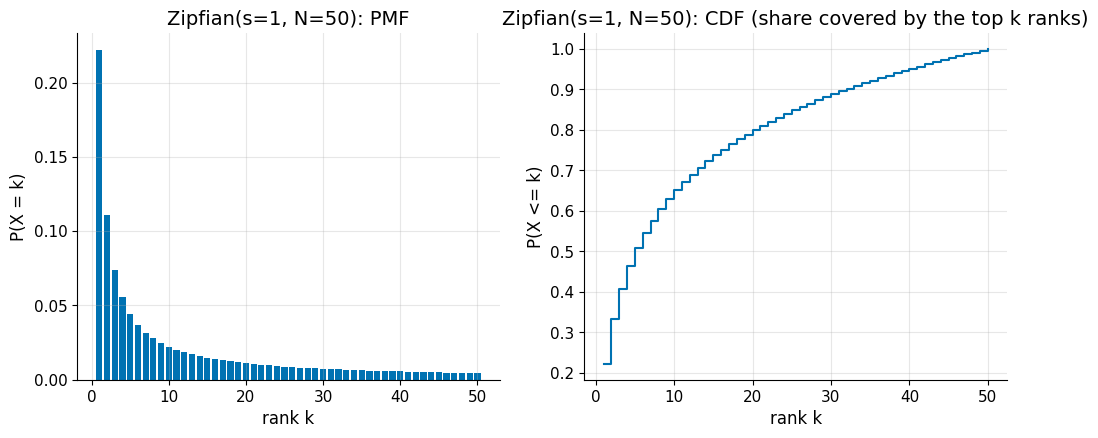

In [2]:
s = 1.0
N = 50
dist = stats.zipfian(a=s, n=N)
ranks = np.arange(1, N + 1)

fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pmf.bar(ranks, dist.pmf(ranks), color=MAIN)
ax_pmf.set_title("Zipfian(s=1, N=50): PMF")
ax_pmf.set_xlabel("rank k")
ax_pmf.set_ylabel("P(X = k)")

ax_cdf.step(ranks, dist.cdf(ranks), where="post", color=MAIN)
ax_cdf.set_title("Zipfian(s=1, N=50): CDF (share covered by the top k ranks)")
ax_cdf.set_xlabel("rank k")
ax_cdf.set_ylabel("P(X <= k)")
plt.show()

### 7.2 Effect of the exponent s
Larger s concentrates the mass on the first few ranks; s near 0 approaches the uniform distribution.

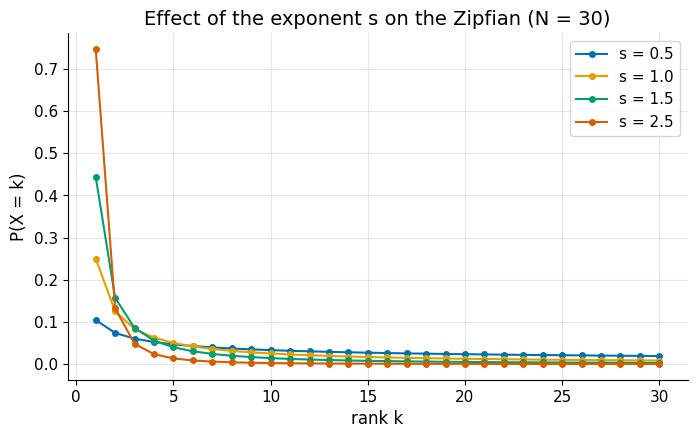

In [3]:
ranks = np.arange(1, 31)
fig, ax = plt.subplots()
for s_value, color in zip([0.5, 1.0, 1.5, 2.5], COLORS):
    ax.plot(ranks, stats.zipfian(a=s_value, n=30).pmf(ranks), "o-", markersize=4, color=color, label=f"s = {s_value}")
ax.set_title("Effect of the exponent s on the Zipfian (N = 30)")
ax.set_xlabel("rank k")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.3 Linear vs log-log view
On linear axes a power law looks like a sharp L-shape; on log-log axes it is a straight line of slope -s.

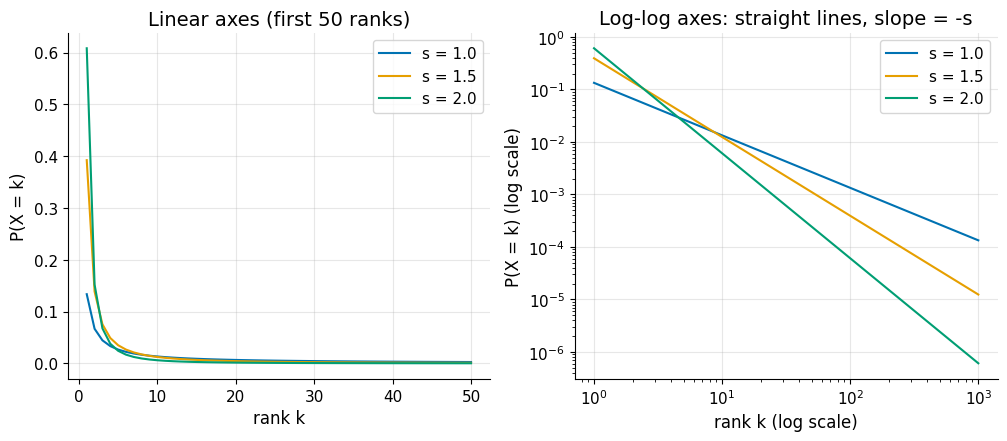

In [4]:
ranks = np.arange(1, 1001)
fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(12, 4.5))
for s_value, color in zip([1.0, 1.5, 2.0], COLORS):
    pmf_values = stats.zipfian(a=s_value, n=1000).pmf(ranks)
    ax_lin.plot(ranks[:50], pmf_values[:50], color=color, label=f"s = {s_value}")
    ax_log.loglog(ranks, pmf_values, color=color, label=f"s = {s_value}")
ax_lin.set_title("Linear axes (first 50 ranks)")
ax_lin.set_xlabel("rank k")
ax_lin.set_ylabel("P(X = k)")
ax_lin.legend()
ax_log.set_title("Log-log axes: straight lines, slope = -s")
ax_log.set_xlabel("rank k (log scale)")
ax_log.set_ylabel("P(X = k) (log scale)")
ax_log.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: PMF over (rank, exponent s)
We plot the base-10 logarithm of the probability so the long tail stays visible. The surface falls as a plane in (log rank, s).

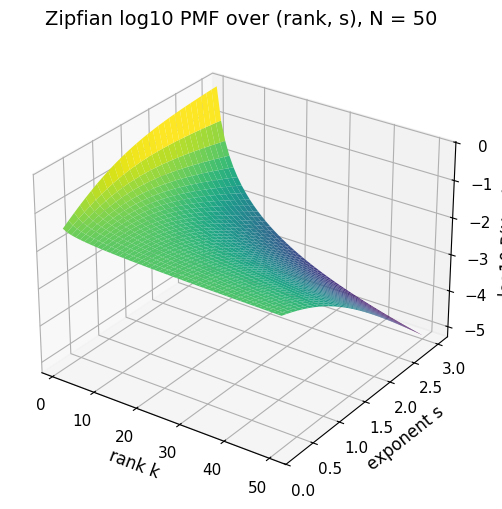

In [5]:
ranks = np.arange(1, 51)
s_values = np.linspace(0.2, 3.0, 29)
R, S = np.meshgrid(ranks, s_values)
Z = np.log10(stats.zipfian.pmf(R, S, 50))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(R, S, Z, cmap="viridis", edgecolor="none")
ax.set_title("Zipfian log10 PMF over (rank, s), N = 50")
ax.set_xlabel("rank k")
ax.set_ylabel("exponent s")
ax.set_zlabel("log10 P(X = k)")
ax.view_init(elev=28, azim=-55)
plt.show()

### 8.2 Static: plain PMF over (rank, s)
Without the log, the mass piles up in the corner of rank 1 and large s.

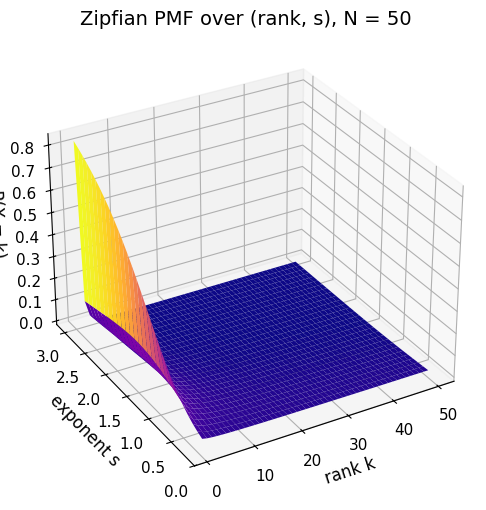

In [6]:
Z_plain = stats.zipfian.pmf(R, S, 50)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(R, S, Z_plain, cmap="plasma", edgecolor="none")
ax.set_title("Zipfian PMF over (rank, s), N = 50")
ax.set_xlabel("rank k")
ax.set_ylabel("exponent s")
ax.set_zlabel("P(X = k)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version
The log10 surface of 8.1; rotate and hover.

In [7]:
fig = go.Figure(go.Surface(x=ranks, y=s_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="Zipfian log10 PMF over (rank, s), N = 50", width=750, height=550,
                  scene=dict(xaxis_title="rank k", yaxis_title="exponent s", zaxis_title="log10 P(X = k)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PMF
Samples from a Zipf distribution with s = 2.5 (finite mean and variance) against the PMF.

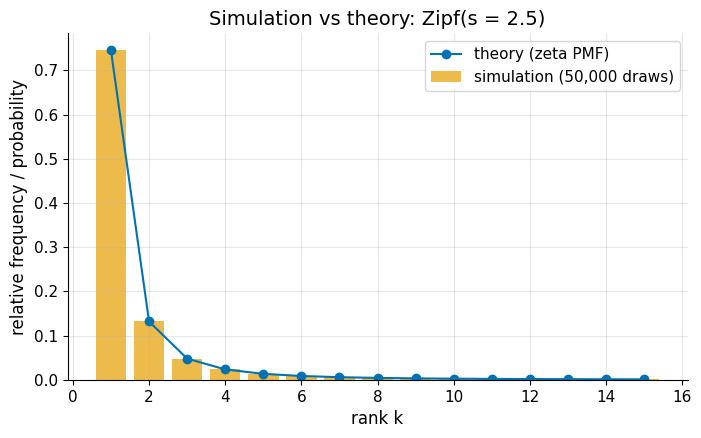

In [8]:
s = 2.5
samples = rng.zipf(a=s, size=50_000)
ranks = np.arange(1, 16)
relative_freq = np.array([np.mean(samples == k) for k in ranks])

fig, ax = plt.subplots()
ax.bar(ranks, relative_freq, color=SIM, alpha=0.7, label="simulation (50,000 draws)")
ax.plot(ranks, stats.zipf(a=s).pmf(ranks), "o-", color=MAIN, label="theory (zeta PMF)")
ax.set_title("Simulation vs theory: Zipf(s = 2.5)")
ax.set_xlabel("rank k")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()

### 9.2 When the running mean fails to converge
The mean is finite only for s above 2. We track the running mean for s = 3.5 (mean exists: it settles), s = 2.5 (mean exists but the variance does not: slow, jumpy), and s = 1.5 (infinite mean: it keeps drifting upward).

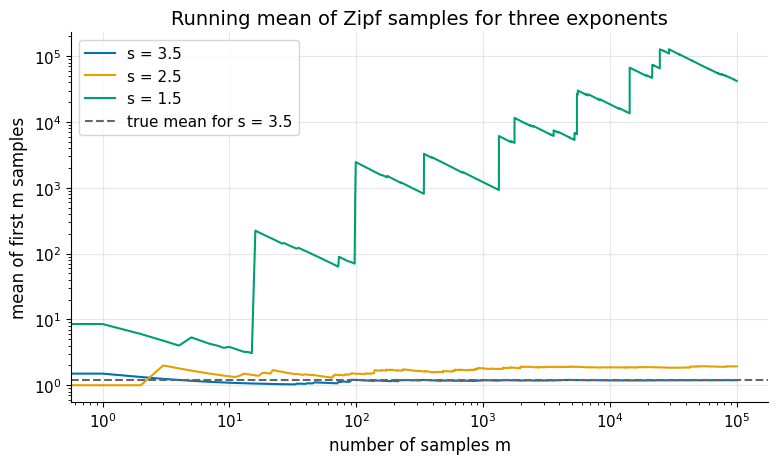

true means: s=3.5 -> 1.191 , s=2.5 -> 1.947 , s=1.5 -> infinite


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for s_value, color in zip([3.5, 2.5, 1.5], COLORS):
    draws = rng.zipf(a=s_value, size=100_000)
    running_mean = np.cumsum(draws) / np.arange(1, len(draws) + 1)
    ax.plot(running_mean, color=color, label=f"s = {s_value}")
ax.axhline(stats.zipf(3.5).mean(), color=NEUTRAL, linestyle="--", label="true mean for s = 3.5")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Running mean of Zipf samples for three exponents")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()
print("true means: s=3.5 ->", round(stats.zipf(3.5).mean(), 3), ", s=2.5 ->", round(stats.zipf(2.5).mean(), 3), ", s=1.5 -> infinite")

## 10. `scipy.stats` cheat sheet

In [10]:
z = stats.zipf(a=2.5)                      # zeta distribution on 1, 2, 3, ... (needs a > 1)
print("zipf pmf(1)        :", round(z.pmf(1), 5))
print("zipf cdf(10)       :", round(z.cdf(10), 5))
print("zipf sf(10)        :", round(z.sf(10), 5))
print("zipf ppf(0.9)      :", z.ppf(0.9))
print("zipf mean, var     :", round(z.mean(), 4), "(var is infinite for a <= 3:", z.var(), ")")
print("zipf rvs(5)        :", z.rvs(size=5, random_state=1))

f = stats.zipfian(a=1.0, n=1000)           # finite vocabulary of 1000 ranks (any a >= 0)
print("zipfian pmf(1)     :", round(f.pmf(1), 5))
print("zipfian cdf(10)    :", round(f.cdf(10), 5), " (top 10 ranks cover this share)")
print("zipfian mean, var  :", round(f.mean(), 2), round(f.var(), 1))

zipf pmf(1)        : 0.74544
zipf cdf(10)       : 0.98541
zipf sf(10)        : 0.01459
zipf ppf(0.9)      : 3.0
zipf mean, var     : 1.9474 (var is infinite for a <= 3: inf )
zipf rvs(5)        : [1 1 1 1 1]
zipfian pmf(1)     : 0.13359
zipfian cdf(10)    : 0.39129  (top 10 ranks cover this share)
zipfian mean, var  : 133.59 49016.0


**Fitting:** `scipy.stats.zipf.fit` is unreliable for this purpose; we fit the exponent by maximum likelihood ourselves in section 11 using `scipy.optimize`.

## 11. Real-world worked example: word frequencies in Pride and Prejudice

**Scenario (real data).** Jane Austen's *Pride and Prejudice* from Project Gutenberg (public domain, source in `../data/README.md`). Each word token has a rank (1 = the most common word). We want to know:
1. Do the word counts follow a power law, and what is the exponent $s$?
2. What share of all words do the **top 10** and **top 100** words cover?
3. How many distinct words are needed to cover **50 %** and **80 %** of the text?

### 11.1 Load and tokenize
We strip the Project Gutenberg header and footer, lowercase everything, and extract words with a regular expression (letters, optionally with an apostrophe such as in "don't").

In [11]:
import pathlib
import re
from collections import Counter

book_path = pathlib.Path("../data/pride_and_prejudice.txt")
if not book_path.exists():
    raise FileNotFoundError("Run `python ../data/download_data.py` first to download the book.")

raw_text = book_path.read_text(encoding="utf-8-sig")
start = raw_text.index("*** START OF")
start = raw_text.index("\n", start)
end = raw_text.index("*** END OF")
body = raw_text[start:end].lower()

words = re.findall(r"[a-z]+(?:'[a-z]+)?", body)
word_counts = Counter(words)
print(f"{len(words):,} word tokens, {len(word_counts):,} distinct words")
print(word_counts.most_common(10))

128,565 word tokens, 6,729 distinct words
[('the', 4663), ('to', 4325), ('of', 3844), ('and', 3767), ('her', 2284), ('i', 2122), ('a', 2038), ('in', 1994), ('was', 1875), ('she', 1751)]


We sort the counts from largest to smallest to get the **frequency by rank** (rank 1 is the most common word) and turn them into probabilities.

In [12]:
sorted_counts = np.array(sorted(word_counts.values(), reverse=True))
n_tokens = sorted_counts.sum()
vocabulary_size = len(sorted_counts)
ranks = np.arange(1, vocabulary_size + 1)
observed_share = sorted_counts / n_tokens          # empirical P(rank = k)
print("share of the most common word:", round(observed_share[0], 4))

share of the most common word: 0.0363


### 11.2 Rank-frequency plot (log-log)
A power law gives a roughly straight line. We overlay the line for s = 1 for comparison.

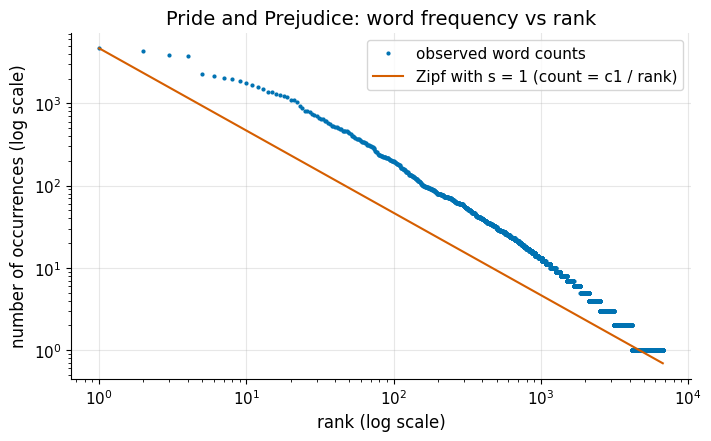

In [13]:
fig, ax = plt.subplots()
ax.loglog(ranks, sorted_counts, ".", color=MAIN, markersize=4, label="observed word counts")
ax.loglog(ranks, sorted_counts[0] / ranks, "-", color=HIGHLIGHT, label="Zipf with s = 1 (count = c1 / rank)")
ax.set_title("Pride and Prejudice: word frequency vs rank")
ax.set_xlabel("rank (log scale)")
ax.set_ylabel("number of occurrences (log scale)")
ax.legend()
plt.show()

### 11.3 Estimating the exponent
**By hand (regression).** On the log-log plot the slope of the line is $-s$. We fit a least-squares line to $\log(\text{count})$ against $\log(\text{rank})$ over the first 1,000 ranks (the noisy tail of words appearing once or twice would flatten it).

**By maximum likelihood.** For the finite Zipfian the log-likelihood of the whole text is $\ell(s)=-s\sum_{r}c_r\ln r-n\ln H_{N,s}$ where $c_r$ is the count of rank $r$. We maximise it numerically.

In [14]:
from scipy import optimize

top_ranks = np.arange(1, 1001)
slope, intercept = np.polyfit(np.log(top_ranks), np.log(sorted_counts[:1000]), deg=1)
s_regression = -slope

def negative_log_likelihood(s):
    harmonic_sum = np.sum(ranks ** (-s))                    # H_{N,s}
    return s * np.sum(sorted_counts * np.log(ranks)) + n_tokens * np.log(harmonic_sum)

result = optimize.minimize_scalar(negative_log_likelihood, bounds=(0.1, 3.0), method="bounded")
s_mle = result.x
print(f"s from log-log regression (ranks 1-1000): {s_regression:.3f}")
print(f"s from maximum likelihood (all ranks)   : {s_mle:.3f}")

s from log-log regression (ranks 1-1000): 1.091
s from maximum likelihood (all ranks)   : 0.995


Both estimates are close to 1 (about 1.09 by regression, 1.00 by maximum likelihood), as Zipf's law predicts. We use the maximum-likelihood value to build the model distribution `stats.zipfian(a=s_mle, n=vocabulary_size)` and compare coverage.

### 11.4 Coverage questions
**By hand.** Coverage of the top $n$ ranks is $\dfrac{H_{n,s}}{H_{N,s}}=\dfrac{\sum_{j=1}^nj^{-s}}{\sum_{j=1}^Nj^{-s}}$. With $s=1$ and $N=6{,}729$: $H_{10}=2.929$, $H_{100}=5.187$, $H_{6729}\approx\ln6729+0.5772=9.39$. So the model with $s=1$ predicts $\frac{2.929}{9.39}=31\%$ for the top 10 and $\frac{5.187}{9.39}=55\%$ for the top 100. The code computes the sums with an explicit loop.

In [15]:
def harmonic_sum(n, s):
    # H_{n,s} = 1^-s + 2^-s + ... + n^-s, written as an explicit loop
    total = 0.0
    for j in range(1, n + 1):
        total += j ** (-s)
    return total

coverage_top10_hand = harmonic_sum(10, 1.0) / harmonic_sum(vocabulary_size, 1.0)
coverage_top100_hand = harmonic_sum(100, 1.0) / harmonic_sum(vocabulary_size, 1.0)

coverage_top10_data = observed_share[:10].sum()
coverage_top100_data = observed_share[:100].sum()
print(f"model s = 1: top 10 covers {coverage_top10_hand:.3f}, top 100 covers {coverage_top100_hand:.3f}")
print(f"actual text: top 10 covers {coverage_top10_data:.3f}, top 100 covers {coverage_top100_data:.3f}")

model s = 1: top 10 covers 0.312, top 100 covers 0.552
actual text: top 10 covers 0.223, top 100 covers 0.586


Now the same coverage from `scipy` (the CDF of the Zipfian is exactly the coverage), with the assert against the hand formula, and the MLE model next to the data.

In [16]:
model_s1 = stats.zipfian(a=1.0, n=vocabulary_size)
model_mle = stats.zipfian(a=s_mle, n=vocabulary_size)

assert np.isclose(coverage_top10_hand, model_s1.cdf(10))
assert np.isclose(coverage_top100_hand, model_s1.cdf(100))
print(f"MLE model (s = {s_mle:.3f}): top 10 covers {model_mle.cdf(10):.3f}, top 100 covers {model_mle.cdf(100):.3f}")

cumulative_share = np.cumsum(observed_share)
words_for_50 = int(np.searchsorted(cumulative_share, 0.50) + 1)
words_for_80 = int(np.searchsorted(cumulative_share, 0.80) + 1)
print(f"distinct words needed to cover 50% of the text: {words_for_50}, 80%: {words_for_80}")

MLE model (s = 0.995): top 10 covers 0.307, top 100 covers 0.546
distinct words needed to cover 50% of the text: 58, 80%: 525


### 11.5 Verify by simulation
We draw a synthetic text of the same length from the fitted model (with `rng.choice`, which is much faster than the generic `rvs` for a vocabulary this large) and compute the same coverage numbers. A Monte Carlo estimate should match the model's exact CDF.

In [17]:
simulated_ranks = rng.choice(ranks, size=n_tokens, p=model_mle.pmf(ranks))      # draw ranks with the model probabilities
coverage_top10_sim = np.mean(simulated_ranks <= 10)
coverage_top100_sim = np.mean(simulated_ranks <= 100)
print(f"top 10: exact {model_mle.cdf(10):.4f}, simulated {coverage_top10_sim:.4f}")
print(f"top 100: exact {model_mle.cdf(100):.4f}, simulated {coverage_top100_sim:.4f}")
assert abs(coverage_top10_sim - model_mle.cdf(10)) < 0.01
assert abs(coverage_top100_sim - model_mle.cdf(100)) < 0.01

top 10: exact 0.3068, simulated 0.3059
top 100: exact 0.5465, simulated 0.5467


### 11.6 Plots with the answers marked
Left: the cumulative coverage curve with the top 10 and top 100 marked. Right: the observed log-log counts with the fitted model and the regression line.

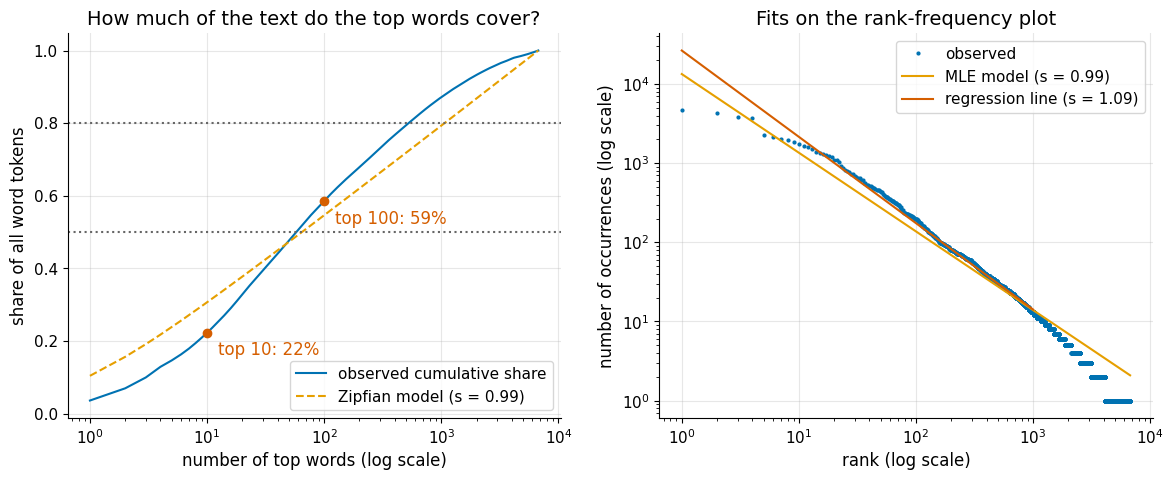

In [18]:
fig, (ax_cover, ax_fit) = plt.subplots(1, 2, figsize=(14, 5))

ax_cover.semilogx(ranks, cumulative_share, color=MAIN, label="observed cumulative share")
ax_cover.semilogx(ranks, model_mle.cdf(ranks), "--", color=SIM, label=f"Zipfian model (s = {s_mle:.2f})")
for n_top, share in [(10, coverage_top10_data), (100, coverage_top100_data)]:
    ax_cover.plot([n_top], [share], "o", color=HIGHLIGHT)
    ax_cover.annotate(f"top {n_top}: {share:.0%}", (n_top, share), textcoords="offset points", xytext=(8, -16), color=HIGHLIGHT, fontsize=12)
ax_cover.axhline(0.5, color=NEUTRAL, linestyle=":")
ax_cover.axhline(0.8, color=NEUTRAL, linestyle=":")
ax_cover.set_title("How much of the text do the top words cover?")
ax_cover.set_xlabel("number of top words (log scale)")
ax_cover.set_ylabel("share of all word tokens")
ax_cover.legend(loc="lower right")

ax_fit.loglog(ranks, sorted_counts, ".", color=MAIN, markersize=4, label="observed")
ax_fit.loglog(ranks, model_mle.pmf(ranks) * n_tokens, "-", color=SIM, label=f"MLE model (s = {s_mle:.2f})")
ax_fit.loglog(top_ranks, np.exp(intercept) * top_ranks ** slope, "-", color=HIGHLIGHT, label=f"regression line (s = {s_regression:.2f})")
ax_fit.set_title("Fits on the rank-frequency plot")
ax_fit.set_xlabel("rank (log scale)")
ax_fit.set_ylabel("number of occurrences (log scale)")
ax_fit.legend()
plt.show()

### 11.7 The other view: frequency of frequencies
How many distinct words occur exactly once, twice, three times...? This count-of-counts is also a power law. Words that appear once are called *hapax legomena*.

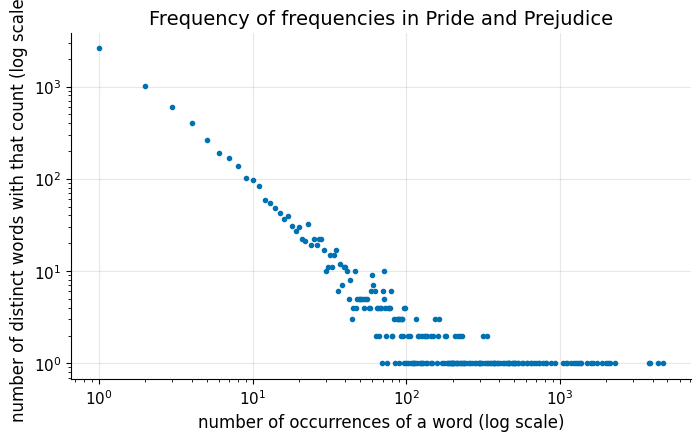

words that occur exactly once: 2,598 (39% of the vocabulary)


In [19]:
frequency_of_frequency = Counter(sorted_counts.tolist())
counts_axis = np.array(sorted(frequency_of_frequency))
number_of_words = np.array([frequency_of_frequency[c] for c in counts_axis])

fig, ax = plt.subplots()
ax.loglog(counts_axis, number_of_words, ".", color=MAIN)
ax.set_title("Frequency of frequencies in Pride and Prejudice")
ax.set_xlabel("number of occurrences of a word (log scale)")
ax.set_ylabel("number of distinct words with that count (log scale)")
plt.show()
print(f"words that occur exactly once: {frequency_of_frequency[1]:,} ({frequency_of_frequency[1] / vocabulary_size:.0%} of the vocabulary)")

### 11.8 Interpretation and decision
- The rank-frequency plot is close to a straight line with slope about -1, so **word use follows a Zipf-like power law**: the ten most common words cover about **22 %** of the text and the top 100 cover about **59 %**.
- To cover **half** of the text you need only **58** distinct words; to cover **80 %** you need **525**; the remaining 20 % is spread over thousands of rare words, and **39 % of the vocabulary (2,598 words) appears just once**.
- The pure s = 1 model overpredicts the very top (31 % for the top 10 vs 22 % observed) but slightly underpredicts the top 100 (55 % vs 59 %): real text is only roughly Zipfian, and the head is flatter (a Zipf-Mandelbrot shape fits better).
- **Decision for an NLP system:** a vocabulary of the top few thousand words covers almost all tokens, but the long tail of rare words never disappears, so a model needs a plan for unseen and rare words (subword tokenization, an "unknown" token). A cache that holds the 100 most popular items would serve more than half of all requests.

## 12. Where it is used

### Statistics
- **Heavy-tailed count data:** power-law tails (city sizes, incomes in discrete units, citation counts).
- **Estimating tail exponents** by maximum likelihood, and testing power laws against alternatives (log-normal, exponential).
- **Infinite moments:** a warning that sample means and variances of such data can be meaningless.

### Data science
- **Popularity and long-tail products:** a few items make most of the sales or views; recommenders must serve the tail too.
- **Cache and CDN design:** the hit rate of a cache holding the top n items is the Zipf CDF.
- **Text analytics:** stop words, vocabulary pruning, TF-IDF all exploit the Zipf shape.

### ML and AI
- **NLP vocabularies and tokenization:** subword methods (BPE, WordPiece) exist because of the long tail of rare words.
- **Language-model data:** token frequencies in training data follow Zipf, which affects rare-token learning and embedding quality.
- **Sampling of rare classes** in long-tailed classification and recommendation benchmarks.

## 13. Common pitfalls and misconceptions

- **Fitting a line to the log-log plot is biased:** the noisy tail (counts of 1 or 2) flattens the slope. Prefer maximum likelihood, or restrict the range.
- **A straight-looking log-log plot is not proof of a power law:** log-normal and other heavy-tailed distributions can look similar over a few decades; test alternatives.
- **Means and variances may not exist.** For s of 2 or less the mean is infinite; do not report sample means as if they converge.
- **Parameter naming:** `stats.zipf(a)` needs a > 1 and has infinite support; `stats.zipfian(a, n)` is finite and allows any a >= 0. Pick the one matching your problem.
- **Rank vs frequency confusion:** the random variable is the rank of a token, not the count.
- **Tokenization choices matter:** lowercasing, punctuation and apostrophes change the vocabulary size and the fit.

## 14. Exercises

1. For Zipf with $s=2$, compute $\zeta(2)=\pi^2/6$ and $P(X=1)$, $P(X\le3)$.
2. For which $s$ is the mean of the zeta distribution finite? The variance? Give the one-line reason.
3. A cache holds the 50 most popular of 10,000 equally sized items; requests follow a Zipfian with $s=1$. What is the hit rate?
4. For a Zipfian with $s=1$ and $N=1000$, how many top ranks cover 50 % of requests?
5. Using code, simulate 10,000 samples of Zipf($s=3.5$) and compare the sample mean and variance with the theory.
6. Repeat the exponent estimate for the first 5,000 words of the book only, and compare to the full-book value. What changes?
7. (Harder) Derive the log-likelihood and the score equation for the finite Zipfian exponent, and show that it equals "expected log-rank = observed average log-rank".
8. (Harder) Show that if the rank-frequency exponent is $s$, the count-of-counts follows a power law with exponent $1+1/s$ (continuous approximation).

Solutions are at the end.

## 15. Summary table

| Item | Zipf (zeta) | Zipfian (finite) |
|---|---|---|
| Parameters | s > 1 | s >= 0, N |
| Support | 1, 2, 3, ... | 1, ..., N |
| PMF | k^(-s) / zeta(s) | k^(-s) / H_{N,s} |
| Mean | zeta(s-1)/zeta(s), needs s > 2 | always finite |
| Variance | needs s > 3 | always finite |
| When to use | heavy-tailed ranks, unbounded | vocabulary or catalogue of fixed size |
| `scipy` name | `stats.zipf(a=s)` | `stats.zipfian(a=s, n=N)` |

## Solutions

In [20]:
z2 = stats.zipf(a=2)
print("1: zeta(2) =", np.pi**2 / 6, " P(1) =", z2.pmf(1), " P(<=3) =", z2.cdf(3))
print("3: hit rate =", stats.zipfian(a=1.0, n=10_000).cdf(50))
cdf_values = stats.zipfian(a=1.0, n=1000).cdf(np.arange(1, 1001))
print("4: ranks needed for 50% =", int(np.argmax(cdf_values >= 0.5) + 1))
draws = rng.zipf(a=3.5, size=10_000)
print("5: sample mean", draws.mean().round(3), "theory", round(stats.zipf(3.5).mean(), 3), "| sample var", draws.var().round(2), "theory", round(stats.zipf(3.5).var(), 2))

first_5000 = Counter(words[:5000])
counts_5000 = np.array(sorted(first_5000.values(), reverse=True))
ranks_5000 = np.arange(1, len(counts_5000) + 1)

def nll_5000(s):
    return s * np.sum(counts_5000 * np.log(ranks_5000)) + counts_5000.sum() * np.log(np.sum(ranks_5000 ** (-s)))

print("6: s (first 5000 words) =", round(optimize.minimize_scalar(nll_5000, bounds=(0.1, 3.0), method="bounded").x, 3), " vs full book", round(s_mle, 3))

1: zeta(2) = 1.6449340668482264  P(1) = 0.6079271018540265  P(<=3) = 0.8274563330790917
3: hit rate = 0.4596839433218296
4: ranks needed for 50% = 24
5: sample mean 1.192 theory 1.191 | sample var 0.68 theory 0.9
6: s (first 5000 words) = 0.874  vs full book 0.995


**1.** $\zeta(2)=\pi^2/6\approx1.645$, $P(X=1)=1/1.645=0.608$, $P(X\le3)=(1+1/4+1/9)/1.645\approx0.827$.

**2.** Mean finite iff $s>2$, variance finite iff $s>3$: the mean needs $\sum k^{1-s}$ to converge ($1-s<-1$), the variance needs $\sum k^{2-s}$ to converge.

**3.** Hit rate $=H_{50}/H_{10000}\approx4.499/9.788\approx0.46$ (printed above).

**4.** Printed above (24 ranks cover half of the requests for 1,000 items).

**5.** The sample mean (1.19) matches the theory. The sample variance is noticeably off (0.68 vs 0.90): the variance exists for $s=3.5$, but the fourth moment is infinite, so the sample variance converges very slowly and is erratic.

**6.** With 5,000 words the estimate is about 0.87 against 0.995 for the whole book: exponent estimates depend on text length (a short text has a smaller vocabulary), which is one reason to report the data size alongside $s$.

**7.** $\ell(s)=-s\sum_i\ln r_i-m\ln H_{N,s}$; $\ell'(s)=-\sum_i\ln r_i+m\frac{\sum_jj^{-s}\ln j}{H_{N,s}}=0\Rightarrow\frac1m\sum_i\ln r_i=\frac{\sum_jj^{-s}\ln j}{H_{N,s}}=E_s[\ln X]$.

**8.** If count $c(r)\propto r^{-s}$ then rank $r(c)\propto c^{-1/s}$. The number of words with count near $c$ is $|dr/dc|\propto c^{-1/s-1}=c^{-(1+1/s)}$.